In [2]:
import qrcode
img = qrcode.make('https://naver.com')
type(img)  # qrcode.image.pil.PilImage
img.save("some_file.png")

# Day1 pandas


## pandas - 데이터 불러오기

### 공통 셀

In [3]:
# ===== 공통 설정 (모든 노트북 첫 셀) =====
import platform
import matplotlib.pyplot as plt
from matplotlib import font_manager
import pandas as pd

# 1) 그래프 한글 폰트
if platform.system() == 'Windows':
    FONT_NAME = 'Malgun Gothic'      # 맑은 고딕
elif platform.system() == 'Darwin':  # Mac
    FONT_NAME = 'AppleGothic'
else:
    FONT_NAME = 'NanumGothic'
plt.rc('font', family=FONT_NAME)
plt.rcParams['axes.unicode_minus'] = False   # 마이너스(-) 깨짐 방지

# 2) 워드클라우드용 폰트 파일 경로 (6장에서 사용)
FONT_PATH = font_manager.findfont(FONT_NAME)

# 3) 표 출력 옵션
pd.set_option('display.unicode.east_asian_width', True)  # 한글 표 줄맞춤
pd.set_option('display.max_columns', None)               # 열 생략(...) 없이 보기
pd.set_option('display.width', 200)

print('설정 완료 | 폰트:', FONT_NAME)

설정 완료 | 폰트: Malgun Gothic


# 시리즈 만들기

In [4]:
import pandas as pd
amount = pd.Series([100, 200, 300, 400, 500.0], 
                    index=['a', 'b', 'c', 'd', 'e'])
# amount.describe()
amount

a    100.0
b    200.0
c    300.0
d    400.0
e    500.0
dtype: float64

# DataFrame

In [6]:
dic = {'메뉴':['아아', '라떼', '뜨아'],
'가격':[3000, 4000, 3000],
'수량':[1,2,3]}

df = pd.DataFrame(dic)
df

,메뉴,가격,수량
0,아아,3000,1
1,라떼,4000,2
2,뜨아,3000,3


In [10]:
print(type(df))
print(type(df['메뉴']))

<class 'pandas.DataFrame'>
<class 'pandas.Series'>


# 데이터 불러오기

In [11]:
# 실습용 데이터 파일 만들기 (한 번만 실행)
from pathlib import Path

Path('data').mkdir(exist_ok=True)
csv_text = """날짜,지점,메뉴,분류,가격,수량,날씨
2026-11-02,강남점,아메리카노,커피,4500,32,맑음
2026-11-02,강남점,카페라테,커피,5000,18,맑음
2026-11-02,강남점,치즈케이크,디저트,6500,7,맑음
2026-11-02,홍대점,아메리카노,커피,4300,41,맑음
2026-11-02,홍대점,자몽에이드,음료,5800,12,맑음
2026-11-03,강남점,아메리카노,커피,4500,28,흐림
2026-11-03,강남점,카페라테,커피,5000,,흐림
2026-11-03,홍대점,카페라테,커피,4800,22,흐림
2026-11-03,홍대점,치즈케이크,디저트,6300,9,흐림
2026-11-03,홍대점,자몽에이드,음료,5800,8,흐림
2026-11-04,강남점,아메리카노,커피,4500,25,비
2026-11-04,강남점,치즈케이크,디저트,6500,11,비
2026-11-04,강남점,자몽에이드,음료,6000,4,비
2026-11-04,홍대점,아메리카노,커피,4300,30,비
2026-11-04,홍대점,카페라테,커피,4800,26,
2026-11-05,강남점,아메리카노,커피,4500,35,맑음
2026-11-05,강남점,카페라테,커피,5000,21,맑음
2026-11-05,홍대점,아메리카노,커피,4300,44,맑음
2026-11-05,홍대점,치즈케이크,디저트,6300,13,맑음
2026-11-05,홍대점,자몽에이드,음료,5800,15,맑음
"""
Path('data/cafe_sales.csv').write_text(csv_text, encoding='utf-8')
print('파일 생성 완료')

파일 생성 완료


In [13]:
df = pd.read_csv(r'data\cafe_sales.csv')
df

,날짜,지점,메뉴,분류,가격,수량,날씨
0,2026-11-02,강남점,아메리카노,커피,4500,32.0,맑음
1,2026-11-02,강남점,카페라테,커피,5000,18.0,맑음
2,2026-11-02,강남점,치즈케이크,디저트,6500,7.0,맑음
3,2026-11-02,홍대점,아메리카노,커피,4300,41.0,맑음
4,2026-11-02,홍대점,자몽에이드,음료,5800,12.0,맑음
5,2026-11-03,강남점,아메리카노,커피,4500,28.0,흐림
6,2026-11-03,강남점,카페라테,커피,5000,NaN,흐림
7,2026-11-03,홍대점,카페라테,커피,4800,22.0,흐림
8,2026-11-03,홍대점,치즈케이크,디저트,6300,9.0,흐림
9,2026-11-03,홍대점,자몽에이드,음료,5800,8.0,흐림


In [20]:
df.describe()

,가격,수량
count,20.000000,19.000000
mean,5225.000000,21.105263
std,805.817663,11.798751
min,4300.000000,4.000000
25%,4500.000000,11.500000
50%,5000.000000,21.000000
75%,5850.000000,29.000000
max,6500.000000,44.000000


# worldcloud 만들기

In [32]:
from matplotlib import font_manager

def find_korean_font():
    # Windows: 맑은 고딕 / Mac: AppleGothic / Linux·Colab: 나눔고딕, Noto Sans CJK
    for name in ['Malgun Gothic', 'AppleGothic', 'NanumGothic', 'Noto Sans CJK KR']:
        try:
            return font_manager.findfont(name, fallback_to_default=False)
        except ValueError:
            pass
    raise FileNotFoundError('한글 폰트를 찾지 못했습니다. 한글 폰트를 설치하세요.')

FONT_PATH = find_korean_font()
print('사용할 폰트:', FONT_PATH)

사용할 폰트: C:\Windows\Fonts\malgun.ttf


In [33]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud
import numpy as np
from PIL import Image
from collections import Counter

data = ['떡볶이', '짬뽕', '떡볶이', '짜장', '탕수육', '짜장', '떡볶이', '햄버거', '맥도날드', '버거킹', '맘스터치', '프랭크버거', '롯데리아', '파이브가이즈', '맥도날드', '버거킹', '맥도날드', '버거킹', '맘스터치', '프랭크버거', '롯데리아']
food_dict = Counter(data)
print(food_dict)

Counter({'떡볶이': 3, '맥도날드': 3, '버거킹': 3, '짜장': 2, '맘스터치': 2, '프랭크버거': 2, '롯데리아': 2, '짬뽕': 1, '탕수육': 1, '햄버거': 1, '파이브가이즈': 1})


In [36]:
import os
print(os.getcwd())

c:\workspace1\src\workspace1


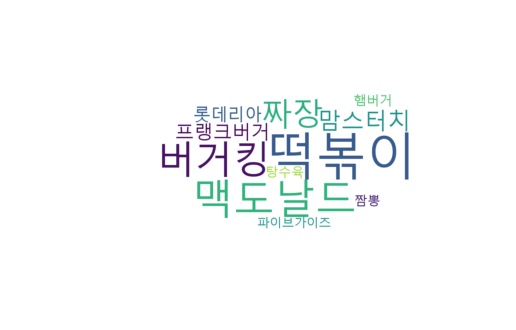

In [39]:
img = Image.open('./제목 없음.png')
img_array = np.array(img)

wc = WordCloud(font_path=FONT_PATH, mask=img_array, background_color='white')

wc = wc.generate_from_frequencies(food_dict)

wc.to_file('wordcloud.png')
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()

[('전쟁', 76), ('폭력', 13), ('경우', 12), ('사람', 9), ('문화', 8), ('군사', 7), ('국가', 6), ('피해', 6), ('세계', 6), ('역사', 5), ('전략', 5), ('동화', 5), ('정치', 4), ('전투', 4), ('경제', 4), ('발전', 4), ('대전', 4), ('과거', 4), ('작전', 4), ('평화', 4)]


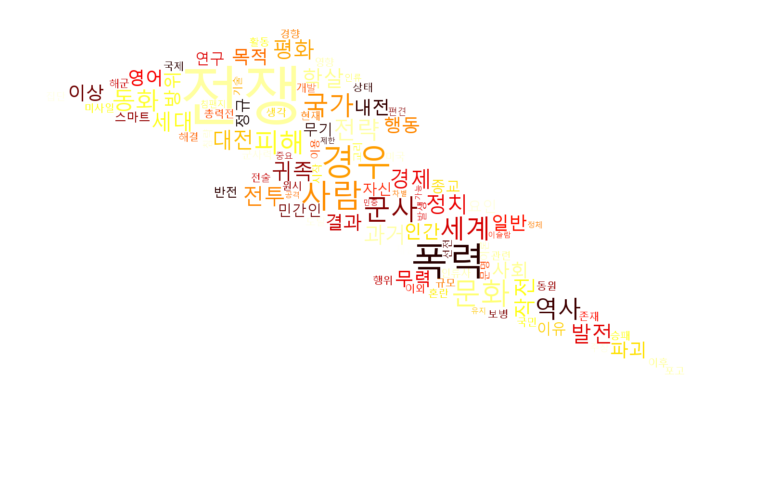

In [45]:
# uv add wikipedia-api kiwipiepy wordcloud matplotlib
import os
from collections import Counter
from urllib.parse import quote

import wikipediaapi
from kiwipiepy import Kiwi
from wordcloud import WordCloud
import matplotlib.pyplot as plt

# 1. 위키백과 문서 수집
wiki = wikipediaapi.Wikipedia(user_agent='edu-nlp-lab/1.0', language='ko')
# title = '공유 (배우)'
title = '전쟁'
page = wiki.page(title)
if not page.exists():
    raise ValueError(f"'{title}' 문서를 찾을 수 없습니다.")

# 괄호가 잘리지 않도록 인코딩한 URL 출력
# print('https://ko.wikipedia.org/wiki/' + quote(page.title.replace(' ', '_')))
text = page.text

# 2. 명사 추출 (일반명사 NNG + 고유명사 NNP, 2글자 이상)
kiwi = Kiwi()
nouns = [t.form for t in kiwi.tokenize(text) if t.tag in ('NNG', 'NNP') and len(t.form) > 1]

# 3. 불용어 제거 후 빈도 계산
stopwords = {'배우', '출연', '작품', '영화', '드라마'}  # 목적에 맞게 조정
freq = Counter(n for n in nouns if n not in stopwords)
if not freq:
    raise ValueError('추출된 명사가 없습니다. 본문 또는 불용어 설정을 확인하세요.')
print(freq.most_common(20))  # 상위 단어 확인용

# 4. 워드클라우드
font_path = FONT_PATH          # 위 「한글 폰트 경로 설정」 셀에서 찾은 폰트
if not os.path.exists(font_path):
    raise FileNotFoundError(f'폰트 파일이 없습니다: {font_path}')

img = Image.open('./thunder.png')
img_array = np.array(img)
wc = WordCloud(font_path=font_path, colormap='hot', background_color='white',mask=img_array, relative_scaling=0.5, width=1000, height=600).generate_from_frequencies(dict(freq.most_common(100)))

plt.figure(figsize=(10, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.show()

In [46]:
from pathlib import Path

if not Path('data/cafe_sales.csv').exists():
    Path('data').mkdir(exist_ok=True)
    csv_text = """날짜,지점,메뉴,분류,가격,수량,날씨
2026-11-02,강남점,아메리카노,커피,4500,32,맑음
2026-11-02,강남점,카페라테,커피,5000,18,맑음
2026-11-02,강남점,치즈케이크,디저트,6500,7,맑음
2026-11-02,홍대점,아메리카노,커피,4300,41,맑음
2026-11-02,홍대점,자몽에이드,음료,5800,12,맑음
2026-11-03,강남점,아메리카노,커피,4500,28,흐림
2026-11-03,강남점,카페라테,커피,5000,,흐림
2026-11-03,홍대점,카페라테,커피,4800,22,흐림
2026-11-03,홍대점,치즈케이크,디저트,6300,9,흐림
2026-11-03,홍대점,자몽에이드,음료,5800,8,흐림
2026-11-04,강남점,아메리카노,커피,4500,25,비
2026-11-04,강남점,치즈케이크,디저트,6500,11,비
2026-11-04,강남점,자몽에이드,음료,6000,4,비
2026-11-04,홍대점,아메리카노,커피,4300,30,비
2026-11-04,홍대점,카페라테,커피,4800,26,
2026-11-05,강남점,아메리카노,커피,4500,35,맑음
2026-11-05,강남점,카페라테,커피,5000,21,맑음
2026-11-05,홍대점,아메리카노,커피,4300,44,맑음
2026-11-05,홍대점,치즈케이크,디저트,6300,13,맑음
2026-11-05,홍대점,자몽에이드,음료,5800,15,맑음
"""
    Path('data/cafe_sales.csv').write_text(csv_text, encoding='utf-8')
    print('파일 생성 완료')
else:
    print('이미 파일이 있습니다')

이미 파일이 있습니다


In [47]:
import pandas as pd
import numpy as np

df = pd.read_csv('data/cafe_sales.csv')

In [51]:
df[(df['지점']=='강남점') & (df['메뉴']=='아메리카노')]

,날짜,지점,메뉴,분류,가격,수량,날씨
0,2026-11-02,강남점,아메리카노,커피,4500,32.0,맑음
5,2026-11-03,강남점,아메리카노,커피,4500,28.0,흐림
10,2026-11-04,강남점,아메리카노,커피,4500,25.0,비
15,2026-11-05,강남점,아메리카노,커피,4500,35.0,맑음


In [ ]:
#비가 오거나 수량이 10보다 작은 데이터
df[(df['날씨']=='비')| (df['수량'] < 10)]

,날짜,지점,메뉴,분류,가격,수량,날씨
2,2026-11-02,강남점,치즈케이크,디저트,6500,7.0,맑음
8,2026-11-03,홍대점,치즈케이크,디저트,6300,9.0,흐림
9,2026-11-03,홍대점,자몽에이드,음료,5800,8.0,흐림
10,2026-11-04,강남점,아메리카노,커피,4500,25.0,비
11,2026-11-04,강남점,치즈케이크,디저트,6500,11.0,비
12,2026-11-04,강남점,자몽에이드,음료,6000,4.0,비
13,2026-11-04,홍대점,아메리카노,커피,4300,30.0,비


In [ ]:
df[(df['가격']=='비')| (df['수량'] < 10)]

In [ ]:
df['메뉴'].value_counts()

메뉴
아메리카노    7
카페라테      5
치즈케이크    4
자몽에이드    4
Name: count, dtype: int64

In [54]:
df

,날짜,지점,메뉴,분류,가격,수량,날씨
0,2026-11-02,강남점,아메리카노,커피,4500,32.0,맑음
1,2026-11-02,강남점,카페라테,커피,5000,18.0,맑음
2,2026-11-02,강남점,치즈케이크,디저트,6500,7.0,맑음
3,2026-11-02,홍대점,아메리카노,커피,4300,41.0,맑음
4,2026-11-02,홍대점,자몽에이드,음료,5800,12.0,맑음
5,2026-11-03,강남점,아메리카노,커피,4500,28.0,흐림
6,2026-11-03,강남점,카페라테,커피,5000,NaN,흐림
7,2026-11-03,홍대점,카페라테,커피,4800,22.0,흐림
8,2026-11-03,홍대점,치즈케이크,디저트,6300,9.0,흐림
9,2026-11-03,홍대점,자몽에이드,음료,5800,8.0,흐림


## 확인 문제
아래 빈 셀에 직접 코드를 작성해 보세요. (위의 `df`가 불러와져 있어야 합니다.)

**문제 1.** 2026년 11월 4일 데이터만 골라 보세요.

In [56]:
# 여기에 코드를 작성하세요
df[df['날짜']=='2026-11-04']

,날짜,지점,메뉴,분류,가격,수량,날씨
10,2026-11-04,강남점,아메리카노,커피,4500,25.0,비
11,2026-11-04,강남점,치즈케이크,디저트,6500,11.0,비
12,2026-11-04,강남점,자몽에이드,음료,6000,4.0,비
13,2026-11-04,홍대점,아메리카노,커피,4300,30.0,비
14,2026-11-04,홍대점,카페라테,커피,4800,26.0,NaN


**문제 2.** 강남점에서 가격이 5,000원 이상인 기록의 `날짜`, `메뉴`, `가격` 열만 보여 주세요.

In [57]:
# 여기에 코드를 작성하세요
df[(df['지점']=='강남점') & (df['가격'] >= 5000)][['날짜', '메뉴', '가격']]

,날짜,메뉴,가격
1,2026-11-02,카페라테,5000
2,2026-11-02,치즈케이크,6500
6,2026-11-03,카페라테,5000
11,2026-11-04,치즈케이크,6500
12,2026-11-04,자몽에이드,6000
16,2026-11-05,카페라테,5000


**문제 3.** `분류`별로 판매 기록이 몇 건인지 세어 보세요.

In [58]:
# 여기에 코드를 작성하세요
df['분류'].value_counts()

분류
커피      12
디저트     4
음료       4
Name: count, dtype: int64

**문제 4.** 커피 중에서 가격이 가장 싼 기록 3개를 보여 주세요.

In [61]:
# 여기에 코드를 작성하세요
df[df['분류']=='커피'].nsmallest(3, '가격')

,날짜,지점,메뉴,분류,가격,수량,날씨
3,2026-11-02,홍대점,아메리카노,커피,4300,41.0,맑음
13,2026-11-04,홍대점,아메리카노,커피,4300,30.0,비
17,2026-11-05,홍대점,아메리카노,커피,4300,44.0,맑음


**문제 5.** 맑은 날 팔린 커피 중에서 수량이 가장 많은 기록 3개를 보여 주세요.

In [62]:
# 여기에 코드를 작성하세요
df[df['날씨']=='맑음'].nlargest(3, '수량')

,날짜,지점,메뉴,분류,가격,수량,날씨
17,2026-11-05,홍대점,아메리카노,커피,4300,44.0,맑음
3,2026-11-02,홍대점,아메리카노,커피,4300,41.0,맑음
15,2026-11-05,강남점,아메리카노,커피,4500,35.0,맑음


**문제 6.** 메뉴 이름에 '케이크'가 들어간 기록의 `날짜`, `지점`, `수량`만 보여 주세요.

In [64]:
# 여기에 코드를 작성하세요
df[df['메뉴'].str.contains('케이크')][['날짜', '지점', '수량']]

,날짜,지점,수량
2,2026-11-02,강남점,7.0
8,2026-11-03,홍대점,9.0
11,2026-11-04,강남점,11.0
18,2026-11-05,홍대점,13.0


**문제 7.** 홍대점과 강남점의 평균 판매 수량을 각각 구하고, 어느 지점이 더 많은지 말해 보세요.
- 심화 : 아직 groupby는 배우지 않았음

In [67]:
# 여기에 코드를 작성하세요
hong = df[df['지점']=='홍대점']['수량'].mean()
gang = df[df['지점']=='강남점']['수량'].mean()
'hong' if hong > gang else 'gang'

'hong'

**문제 8.** 가격이 4,500원 이상 5,000원 이하인 기록에서 메뉴별 건수를 세어 보세요.

In [68]:
# 여기에 코드를 작성하세요
df[(df['가격'] >=4500) & (df['가격'] <= 5000)]

,날짜,지점,메뉴,분류,가격,수량,날씨
0,2026-11-02,강남점,아메리카노,커피,4500,32.0,맑음
1,2026-11-02,강남점,카페라테,커피,5000,18.0,맑음
5,2026-11-03,강남점,아메리카노,커피,4500,28.0,흐림
6,2026-11-03,강남점,카페라테,커피,5000,NaN,흐림
7,2026-11-03,홍대점,카페라테,커피,4800,22.0,흐림
10,2026-11-04,강남점,아메리카노,커피,4500,25.0,비
14,2026-11-04,홍대점,카페라테,커피,4800,26.0,NaN
15,2026-11-05,강남점,아메리카노,커피,4500,35.0,맑음
16,2026-11-05,강남점,카페라테,커피,5000,21.0,맑음


**문제 9.** 수량이 10개 미만인 기록은 몇 건인가요?

In [69]:
# 여기에 코드를 작성하세요
df[df['수량'] < 10]

,날짜,지점,메뉴,분류,가격,수량,날씨
2,2026-11-02,강남점,치즈케이크,디저트,6500,7.0,맑음
8,2026-11-03,홍대점,치즈케이크,디저트,6300,9.0,흐림
9,2026-11-03,홍대점,자몽에이드,음료,5800,8.0,흐림
12,2026-11-04,강남점,자몽에이드,음료,6000,4.0,비


**문제 10. (생각해 보기)** `info()`에서 수량 열이 `int64`가 아니라 `float64`로 나온 이유를 한 문장으로 설명해 보세요.

**답:** (여기에 작성하세요) 정수가 아닌 실수로 입력되어 있어서